# Forward model of the Gaia DR3 selection function

This tutorial shows how to query the forward model of the Gaia DR3 survey selection function of
[Castro-Ginard et al. (2026)](https://arxiv.org/abs/2610.32551): the probability that a source with a given
sky position and $G$ magnitude is included in Gaia DR3. It reproduces the all-sky maps and the
magnitude dependence shown in the paper.

The model is provided as a precomputed table on HEALPix order 7 (nested, ICRS; about 0.2 deg$^2$ per pixel)
and 105 magnitude bins of width 0.2 mag between $G=1$ and $G=22$. Together with the selection probability,
the table contains the recovered effective scanning law in each pixel.
The data products are archived on Zenodo: [10.5281/zenodo.24190089](https://doi.org/10.5281/zenodo.24190089).

## Loading the model

The model is queried through the class ``DR3SelectionFunctionForwardModel``. On first use, the package
downloads the file **dr3-forward-model-hpx7.h5** (about 66 MB) from Zenodo into the GaiaUnlimited data
directory (``~/.gaiaunlimited`` by default, or ``$GAIAUNLIMITED_DATADIR``). Later calls read the local copy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
import astropy.units as u
from astropy.coordinates import SkyCoord
from matplotlib import cm
from matplotlib.colors import Normalize, TwoSlopeNorm

from gaiaunlimited.selectionfunctions import DR3SelectionFunctionForwardModel
from gaiaunlimited.utils import get_healpix_centers

dr3_sf = DR3SelectionFunctionForwardModel()

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


## Querying the selection probability

``query`` takes the sky coordinates as an astropy ``SkyCoord`` (any frame) and an array of $G$ magnitudes
with the same shape. A single position and magnitude returns a scalar:

In [2]:
c = SkyCoord(ra=10.0, dec=-10.0, unit="deg", frame="icrs")
print(dr3_sf.query(c, 20.8))

0.9883461968916136


For several sources, pass arrays of the same shape:

In [3]:
coords = SkyCoord(l=[0.0, 90.0, 180.0, 280.5] * u.deg, b=[-5.0, 60.0, 10.0, -32.9] * u.deg, frame="galactic")
gmag = np.array([20.5, 20.5, 21.0, 21.0])
print(dr3_sf.query(coords, gmag))

[0.12654518 0.99998274 0.45933132 0.86911334]


The magnitude bins are 0.2 mag wide and closed on the right, $(G_{\rm lo}, G_{\rm hi}]$:
$G=20.9$ and $G=21.0$ both fall in the bin $(20.8, 21.0]$.

**The selection function should not be used at $G>21$.** There, the model overestimates the completeness
of point sources, because of extended sources whose $G$ magnitude is underestimated by Gaia
(Sect. 5.3 of the paper).

## The effective scanning law (Fig. 2 of the paper)

The model recovers an effective, data-driven scanning law: the effective number of scans $N_{\rm eff}$ in
each pixel. ``query_effective_scanning_law`` returns a dictionary with:

* ``N_eff``: posterior median of the effective number of scans;
* ``N_usable``: number of usable scans;
* ``N_error``: posterior width of $N_{\rm eff}$ (difference between the 84th and 16th percentiles).

To make all-sky maps we query the centres of all order-7 HEALPix pixels. ``get_healpix_centers`` returns them
in RING order by default, which is what ``healpy`` plotting functions expect.

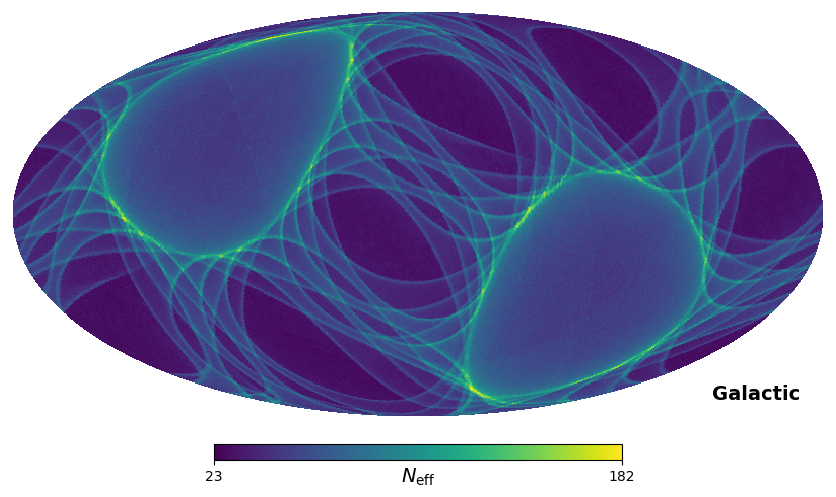

In [4]:
coords_of_centers = get_healpix_centers(7)
scanning_law = dr3_sf.query_effective_scanning_law(coords_of_centers)

hp.mollview(scanning_law["N_eff"], coord=["Celestial", "Galactic"], title="", unit=r"$N_{\rm eff}$")

The posterior on $N_{\rm eff}$ is tightly constrained: its width is zero for about 90% of the pixels.

In [5]:
values, counts = np.unique(scanning_law["N_error"], return_counts=True)
for v, n in zip(values, counts):
    print(f"N_error = {v:.0f}: {n} pixels")

N_error = 0: 176799 pixels
N_error = 1: 19738 pixels
N_error = 2: 61 pixels
N_error = 3: 3 pixels
N_error = 4: 3 pixels
N_error = 5: 2 pixels
N_error = 6: 1 pixels
N_error = 8: 1 pixels


## All-sky maps at the faint end (Fig. 4 of the paper)

The selection probability at four magnitude bins towards Gaia's faint end. Completeness drops with magnitude,
affecting crowded regions first (the Galactic centre) and less-scanned regions second.

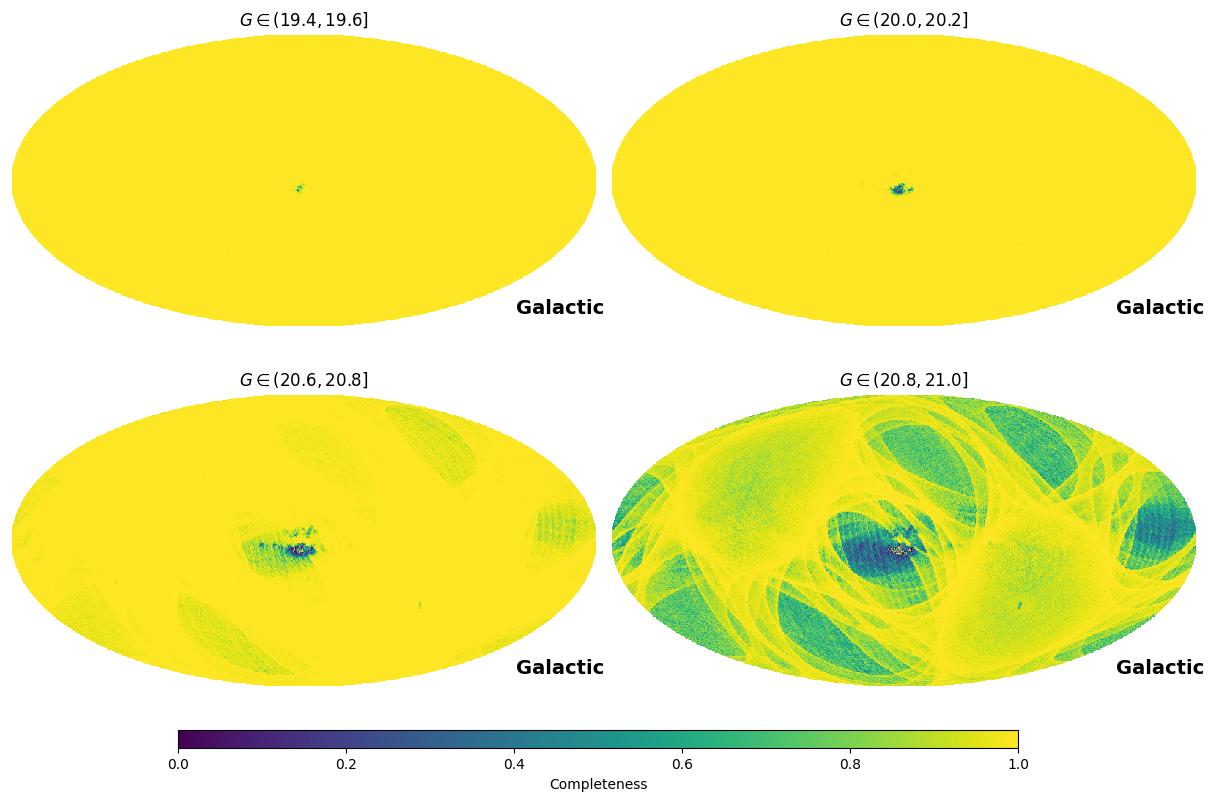

In [6]:
Gmags = np.array([19.5, 20.1, 20.7, 21.0])
titles = [r"$G \in (19.4, 19.6]$", r"$G \in (20.0, 20.2]$", r"$G \in (20.6, 20.8]$", r"$G \in (20.8, 21.0]$"]

cmap = plt.get_cmap("viridis")
fig = plt.figure(figsize=(12, 9))
for panel, (g, title) in enumerate(zip(Gmags, titles), start=1):
    prob_map = dr3_sf.query(coords_of_centers, np.full(len(coords_of_centers), g))
    hp.mollview(prob_map, coord=["Celestial", "Galactic"], min=0, max=1, cmap=cmap,
                title=title, fig=fig.number, sub=(2, 2, panel), cbar=False)

# pull the two rows closer together, as in the paper
for ax in fig.axes[:2]:
    pos = ax.get_position()
    ax.set_position([pos.x0, pos.y0 - 0.05, pos.width, pos.height])
for ax in fig.axes[2:4]:
    pos = ax.get_position()
    ax.set_position([pos.x0, pos.y0 + 0.05, pos.width, pos.height])

cbar_ax = fig.add_axes([0.15, 0.06, 0.7, 0.02])
fig.colorbar(cm.ScalarMappable(cmap=cmap, norm=Normalize(0, 1)), cax=cbar_ax,
             orientation="horizontal", label="Completeness")

## Comparison with other DR3 selection functions (Fig. 5 of the paper)

GaiaUnlimited also provides the empirical model of [Cantat-Gaudin et al. (2023)](https://ui.adsabs.harvard.edu/abs/2023A%26A...669A..55C)
(``DR3SelectionFunctionTCG``) and the forward model of
[Everall & Boubert (2022)](https://ui.adsabs.harvard.edu/abs/2022MNRAS.509.6205E) (``DR3SelectionFunction``),
so the three can be compared at $G \in (20.8, 21.0]$. The last panel compares our effective scanning law with the
number of scans used by Everall & Boubert (2022), $N_{\rm GaiaVerse}$.

**Note:** the first time it is used, ``DR3SelectionFunction`` downloads about 210 MB.
The paper used the original ``selectionfunctions`` package for the Everall & Boubert (2022) panels, so these
two panels differ slightly from Fig. 5 of the paper (GaiaUnlimited's port uses nearest-neighbour interpolation
and its own HEALPix order 10 map of the number of scans).

In [7]:
from gaiaunlimited import utils
from gaiaunlimited.selectionfunctions import DR3SelectionFunction, DR3SelectionFunctionTCG

g = np.full(len(coords_of_centers), 20.9)
p_this_work = dr3_sf.query(coords_of_centers, g)
p_cg23 = DR3SelectionFunctionTCG().query(coords_of_centers, g)

eb22 = DR3SelectionFunction()
p_eb22 = eb22.query(coords_of_centers, g)

# Everall & Boubert (2022) number of scans at each pixel centre
ipix_eb22 = utils.coord2healpix(coords_of_centers, "icrs", eb22.nside_n_field)
n_gaiaverse = eb22.ds["n_field"].sel(ipix=ipix_eb22).to_numpy().astype(float)
diff = n_gaiaverse - scanning_law["N_eff"]
print(f"median N_GaiaVerse - N_eff = {np.median(diff):.0f} scans")

median N_GaiaVerse - N_eff = -9 scans


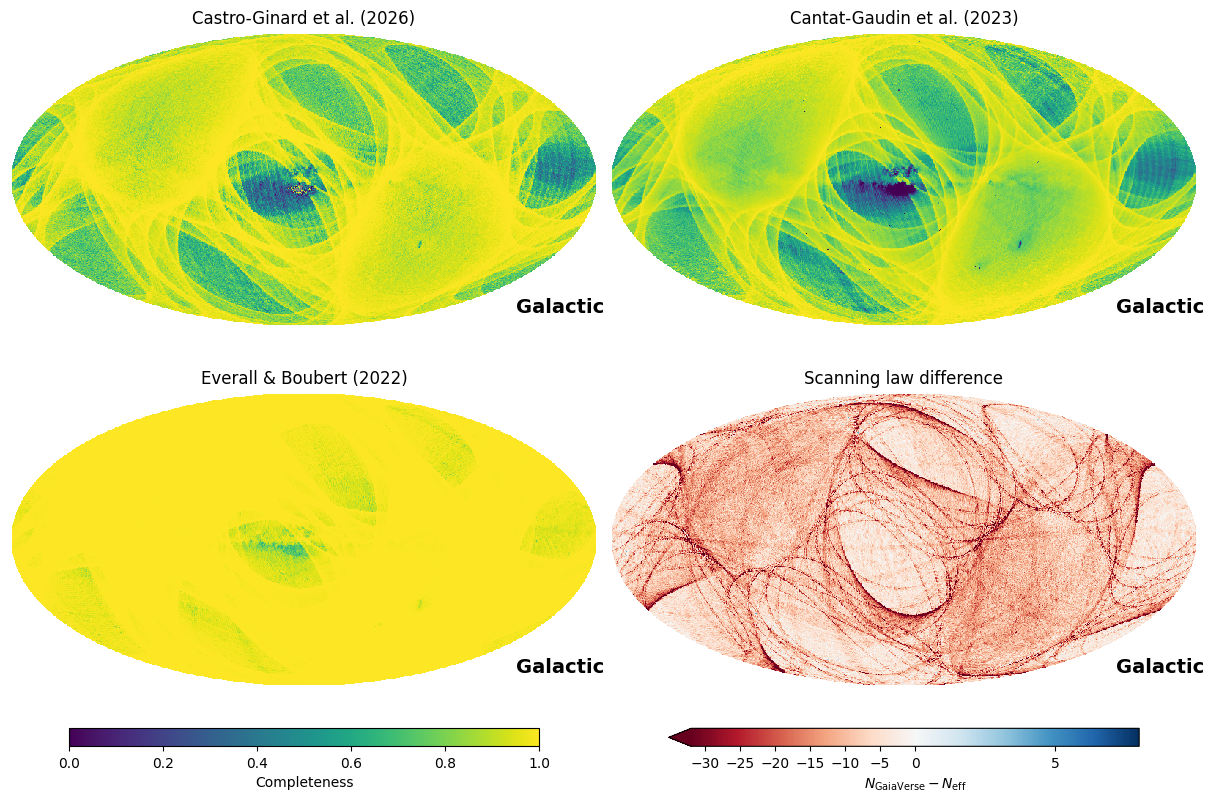

In [8]:
cmap_comp, cmap_diff = plt.get_cmap("viridis"), plt.get_cmap("RdBu")
lo, hi = np.percentile(diff, 1), max(diff.max(), 1)  # clip the rare negative tail
norm_diff = TwoSlopeNorm(vmin=lo, vcenter=0, vmax=hi)

maps = [p_this_work, p_cg23, p_eb22, norm_diff(np.clip(diff, lo, hi))]
titles = ["Castro-Ginard et al. (2026)", "Cantat-Gaudin et al. (2023)",
          "Everall & Boubert (2022)", "Scanning law difference"]
cmaps = [cmap_comp] * 3 + [cmap_diff]

fig = plt.figure(figsize=(12, 9))
for panel, (m, title, cmap) in enumerate(zip(maps, titles, cmaps), start=1):
    hp.mollview(m, coord=["Celestial", "Galactic"], min=0, max=1, cmap=cmap,
                title=title, fig=fig.number, sub=(2, 2, panel), cbar=False)

# pull the two rows closer together, as in the paper
for ax in fig.axes[:2]:
    pos = ax.get_position()
    ax.set_position([pos.x0, pos.y0 - 0.05, pos.width, pos.height])
for ax in fig.axes[2:4]:
    pos = ax.get_position()
    ax.set_position([pos.x0, pos.y0 + 0.05, pos.width, pos.height])

axes = fig.axes
for ax, cmap, norm, label, extend in [(axes[2], cmap_comp, Normalize(0, 1), "Completeness", "neither"),
                                      (axes[3], cmap_diff, norm_diff, r"$N_{\rm GaiaVerse} - N_{\rm eff}$", "min")]:
    pos = ax.get_position()
    cax = fig.add_axes([pos.x0 + 0.1 * pos.width, 0.06, 0.8 * pos.width, 0.02])
    fig.colorbar(cm.ScalarMappable(cmap=cmap, norm=norm), cax=cax, orientation="horizontal",
                 label=label, extend=extend)

## The Galactic centre (Fig. 6 of the paper)

Zooming in on the Galactic centre at $G \in (20.8, 21.0]$. Grey pixels in the top panel are those where Gaia
reports no source in this magnitude bin, so our model gives no estimate (``NaN``).

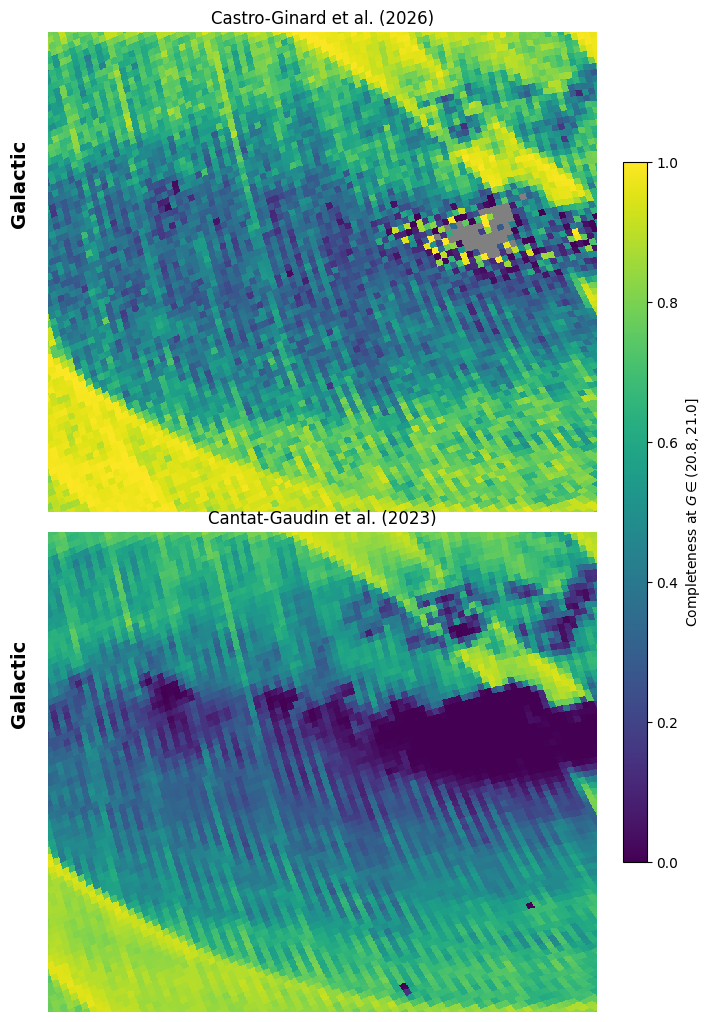

In [9]:
fig = plt.figure(figsize=(8, 10))
for panel, (m, title) in enumerate(zip([p_this_work, p_cg23],
                                       ["Castro-Ginard et al. (2026)", "Cantat-Gaudin et al. (2023)"]), start=1):
    hp.cartview(m, coord=["Celestial", "Galactic"], lonra=[-5, 35], latra=[-25, 10], min=0, max=1,
                cmap=cmap_comp, title=title, fig=fig.number, sub=(2, 1, panel), cbar=False)

cbar_ax = fig.add_axes([0.88, 0.15, 0.03, 0.7])
fig.colorbar(cm.ScalarMappable(cmap=cmap_comp, norm=Normalize(0, 1)), cax=cbar_ax,
             label=r"Completeness at $G \in (20.8, 21.0]$")
plt.subplots_adjust(right=0.85, hspace=0.35)

## Selection probability as a function of magnitude (Fig. 7 of the paper)

The full table is stored as ``dr3_sf.p``, an array of shape (number of pixels, number of magnitude bins), with the
bin centres in ``dr3_sf.g_centers``. Summarising it over the sky gives the sky-averaged selection function.
Pixel–magnitude cells with no Gaia source have no estimate (``NaN``) and are left out of the statistics; the dotted
line shows the fraction of non-empty pixels in each magnitude bin.

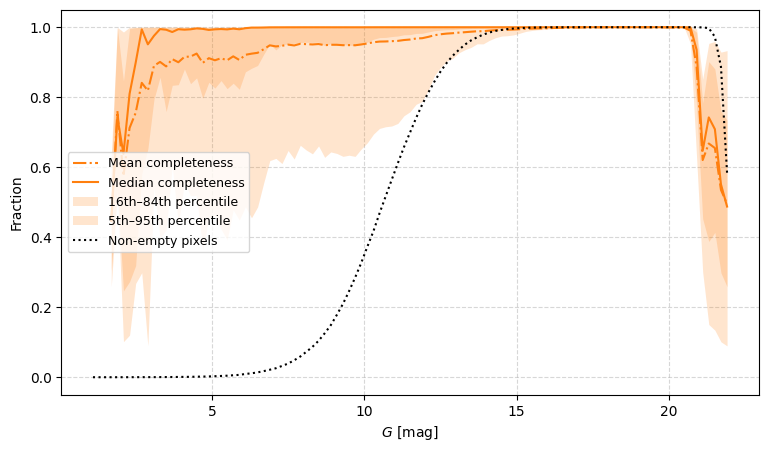

In [10]:
import warnings

g_centers = dr3_sf.g_centers
with warnings.catch_warnings():  # all-NaN columns at the bright end
    warnings.simplefilter("ignore", category=RuntimeWarning)
    p_mean = np.nanmean(dr3_sf.p, axis=0)
    p_median = np.nanmedian(dr3_sf.p, axis=0)
    p05, p16, p84, p95 = np.nanpercentile(dr3_sf.p, [5, 16, 84, 95], axis=0)
frac_non_empty = np.mean(~np.isnan(dr3_sf.p), axis=0)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(g_centers, p_mean, ls="-.", c="C1", label="Mean completeness")
ax.plot(g_centers, p_median, c="C1", label="Median completeness")
ax.fill_between(g_centers, p16, p84, alpha=0.2, color="C1", lw=0, label="16th–84th percentile")
ax.fill_between(g_centers, p05, p95, alpha=0.2, color="C1", lw=0, label="5th–95th percentile")
ax.plot(g_centers, frac_non_empty, ls=":", c="k", label="Non-empty pixels")
ax.set_xlabel(r"$G$ [mag]")
ax.set_ylabel("Fraction")
ax.grid(True, ls="--", lw=0.8, alpha=0.5)
ax.set_axisbelow(True)
ax.legend(loc="center left", fontsize=9);

Gaia DR3 is essentially complete over most of the sky across $5 < G < 19.5$, and the sky-averaged
completeness stays close to 1 until $G \approx 20.7$, then drops sharply. At $G \lesssim 15$ the scatter grows
because fewer and fewer pixels contain sources in each magnitude bin.

## Comparison at the faint end (Fig. 8 of the paper)

A zoom on the faint end, with the empirical model of Cantat-Gaudin et al. (2023) queried at the same bin centres.
The rise of our model at $G \gtrsim 21$ comes from extended sources with underestimated $G$ magnitudes
(Sect. 5.3 of the paper), which is why the model should not be used at $G > 21$.

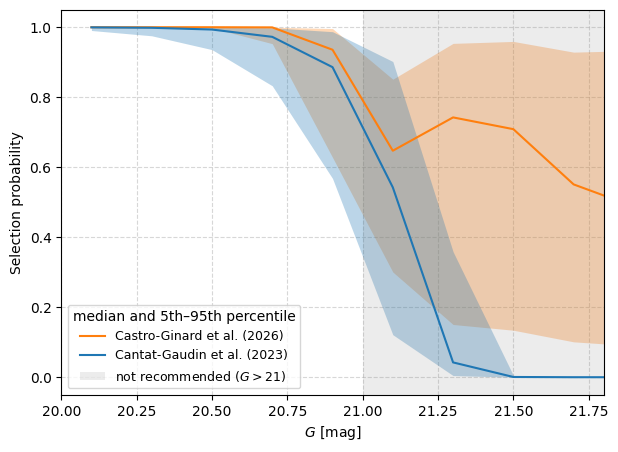

In [11]:
tcg = DR3SelectionFunctionTCG()
faint = g_centers >= 20
cg23_median, cg23_p05, cg23_p95 = [], [], []
for g in g_centers[faint]:
    p = tcg.query(coords_of_centers, np.full(len(coords_of_centers), g))
    cg23_median.append(np.median(p))
    cg23_p05.append(np.percentile(p, 5))
    cg23_p95.append(np.percentile(p, 95))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(g_centers[faint], p_median[faint], c="C1", label="Castro-Ginard et al. (2026)")
ax.fill_between(g_centers[faint], p05[faint], p95[faint], alpha=0.3, color="C1", lw=0)
ax.plot(g_centers[faint], cg23_median, c="C0", label="Cantat-Gaudin et al. (2023)")
ax.fill_between(g_centers[faint], cg23_p05, cg23_p95, alpha=0.3, color="C0", lw=0)
ax.axvspan(21, 22, color="grey", alpha=0.15, lw=0, label="not recommended ($G > 21$)")
ax.set_xlim(20, 21.8)
ax.set_xlabel(r"$G$ [mag]")
ax.set_ylabel("Selection probability")
ax.grid(True, ls="--", lw=0.8, alpha=0.5)
ax.set_axisbelow(True)
ax.legend(loc="lower left", title="median and 5th–95th percentile", fontsize=9);

## Where the model gives no estimate

``query`` returns ``NaN`` in two cases:

* the $G$ magnitude is outside the tabulated range $[1, 22]$;
* the pixel has no Gaia source in that magnitude bin (mostly at the bright end; see the dotted line above).

In [12]:
c = SkyCoord(ra=10.0, dec=-10.0, unit="deg", frame="icrs")
print("G = 8:   ", dr3_sf.query(c, 8.0))
print("G = 22.5:", dr3_sf.query(c, 22.5))

G = 8:    nan
G = 22.5: nan


How to treat these cells depends on the science case, so the package does not fill them.
For example, a user who decides to treat bright sources without an estimate as fully selected can do so explicitly:

In [13]:
prob = dr3_sf.query(coords_of_centers, np.full(len(coords_of_centers), 8.0))
prob_filled = np.where(np.isnan(prob), 1.0, prob)

## Citation

If you use this model in a publication, please cite
[Castro-Ginard et al. (2026)](https://arxiv.org/abs/2610.32551). The BibTeX entry is available as:

In [14]:
print(DR3SelectionFunctionForwardModel.__bibtex__)


        @ARTICLE{2026arXiv261032551C,
                    author = {{Castro-Ginard}, Alfred and {Brown}, Anthony G.~A. and {Belotto Evangelista}, Eduardo and {Portell}, Jordi and {Casey}, Andrew R. and {Drimmel}, Ronald and {Sellentin}, Elena and {Cantat-Gaudin}, Tristan and {Fouesneau}, Morgan and {Khanna}, Shourya and et al.},
                    title = "{Forward model of the Gaia DR3 selection function}",
                    journal = {arXiv e-prints},
                    keywords = {Astrophysics of Galaxies, Instrumentation and Methods for Astrophysics},
                    year = 2026,
                    month = oct,
                    eid = {arXiv:2610.32551},
                    pages = {arXiv:2610.32551},
                    doi = {10.48550/arXiv.2610.32551},
                    archivePrefix = {arXiv},
                    eprint = {2610.32551},
                    primaryClass = {astro-ph.GA},
                    adsurl = {https://ui.adsabs.harvard.edu/abs/2026arXiv2610325